In [17]:
%pip -q install "scikit-learn>=1.4" "matplotlib>=3.8" "joblib>=1.3"

import copy
import hashlib
import io
import json
import math
import random
import time
import urllib.request
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, log_loss, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer, StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset


In [18]:
# Exact settings used for the submitted production run.
from google.colab import drive
drive.mount("/content/drive")

SEED = 684
RUN_ID = "tabddpm_v1"
ARTIFACT_DIR = Path("/content/drive/MyDrive/mia_task_a/tabddpm_v1")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

N_SYNTHETIC = 9_000
DIFFUSION_STEPS = 200
GENERATOR_TRAIN_STEPS = 20_000
GENERATOR_BATCH_SIZE = 1_024
GENERATOR_LEARNING_RATE = 2e-4
GENERATOR_WIDTH = 512
GENERATOR_DEPTH = 4
EMA_DECAY = 0.999
SAMPLE_BATCH_SIZE = 2_048
TARGET_EPOCHS = 50
TARGET_BATCH_SIZE = 128
TARGET_LEARNING_RATE = 1e-3
TARGET_WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cuda")
if not torch.cuda.is_available():
    raise RuntimeError("Select a Colab GPU runtime before running this notebook.")

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False), encoding="utf-8")

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

def sha256_file(path):
    with open(path, "rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

seed_everything(SEED)
print("Device:", DEVICE, "| Artifacts:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Artifacts: /content/drive/MyDrive/mia_task_a/tabddpm_v1


,0
revision,3
generator,class_conditional_tabddpm
seed,684
n_synthetic,9000
max_real_rows,25000
max_eval_rows,10000
min_category_count,25
ddpm,"{'timesteps': 200, 'train_steps': 20000, 'batc..."
target_training,"{'epochs': 50, 'batch_size': 128, 'lr': 0.001,..."
production_run,True


In [19]:
SOURCE_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
source_dir = ARTIFACT_DIR.parent / "source"
source_dir.mkdir(parents=True, exist_ok=True)
source_zip = source_dir / "uci_diabetes_296.zip"
if not source_zip.exists():
    with urllib.request.urlopen(SOURCE_URL, timeout=120) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        assert archive.testzip() is None
    source_zip.write_bytes(archive_bytes)
with zipfile.ZipFile(source_zip) as archive:
    csv_name = next(n for n in archive.namelist() if n.endswith("diabetic_data.csv"))
    with archive.open(csv_name) as stream:
        source = pd.read_csv(stream, dtype=str, keep_default_na=False, na_values=["?", ""])

allowed_labels = {"<30", ">30", "NO"}
if source["readmitted"].isna().any() or not source["readmitted"].isin(allowed_labels).all():
    raise ValueError("Unexpected readmission label.")
source["target"] = (source["readmitted"] == "<30").astype("int64")
excluded_dispositions = {"11", "13", "14", "19", "20", "21"}
source = source.loc[~source["discharge_disposition_id"].isin(excluded_dispositions)].reset_index(drop=True)
assert source["patient_nbr"].notna().all()

outer = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
fit_idx, remainder_idx = next(outer.split(source, groups=source["patient_nbr"]))
remainder = source.iloc[remainder_idx]
inner = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED + 1)
val_local, test_local = next(inner.split(remainder, groups=remainder["patient_nbr"]))
val_idx, real_test_idx = remainder_idx[val_local], remainder_idx[test_local]
patient_sets = [set(source.iloc[idx]["patient_nbr"]) for idx in [fit_idx, val_idx, real_test_idx]]
assert all(patient_sets[i].isdisjoint(patient_sets[j]) for i in range(3) for j in range(i + 1, 3))
np.savez_compressed(ARTIFACT_DIR / "real_partition_row_indices.npz",
                    generator_train=fit_idx, generator_validation=val_idx, utility_test=real_test_idx)

NUMERIC = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
           "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
CORE_CATEGORICAL = ["race", "gender", "age", "admission_type_id",
                    "discharge_disposition_id", "admission_source_id",
                    "diag_1", "diag_2", "diag_3", "max_glu_serum", "A1Cresult"]
MEDICATION_CANDIDATES = ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide", "tolbutamide",
    "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone",
    "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone"]
MEDICATIONS = [c for c in MEDICATION_CANDIDATES if source.iloc[fit_idx][c].nunique(dropna=False) > 1]
GENERATED_FEATURES = NUMERIC + CORE_CATEGORICAL + MEDICATIONS
DERIVED_FEATURES = ["change", "diabetesMed"]
FEATURES = GENERATED_FEATURES + DERIVED_FEATURES
CATEGORICAL_GENERATED = CORE_CATEGORICAL + MEDICATIONS
CATEGORICAL = CATEGORICAL_GENERATED + DERIVED_FEATURES
CODED_CATEGORICAL = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

def diagnosis_group(value):
    if pd.isna(value):
        return "missing"
    text = str(value).strip().upper()
    if text.startswith(("V", "E")):
        return "supplementary"
    try:
        category = int(float(text))
    except (ValueError, OverflowError):
        return "other"
    if category == 250:
        return "diabetes"
    if 390 <= category <= 459 or category == 785:
        return "circulatory"
    if 460 <= category <= 519 or category == 786:
        return "respiratory"
    if 520 <= category <= 579 or category == 787:
        return "digestive"
    if 800 <= category <= 999:
        return "injury"
    if 710 <= category <= 739:
        return "musculoskeletal"
    if 580 <= category <= 629 or category == 788:
        return "genitourinary"
    if 140 <= category <= 239:
        return "neoplasm"
    return "other"

def clean_generated_columns(frame):
    data = frame.copy()
    for col in ["A1Cresult", "max_glu_serum"]:
        data[col] = data[col].replace({"None": "not_measured"})
    for col in ["diag_1", "diag_2", "diag_3"]:
        data[col] = data[col].map(diagnosis_group)
    for col in NUMERIC:
        data[col] = pd.to_numeric(data[col], errors="raise").astype("int64")
    for col in CODED_CATEGORICAL:
        data[col] = data[col].map(lambda x: str(int(x)) if pd.notna(x) else "missing")
    for col in CATEGORICAL_GENERATED:
        data[col] = data[col].fillna("missing").astype(str)
    return data[GENERATED_FEATURES + ["target"]].reset_index(drop=True)

fit_clean = clean_generated_columns(source.iloc[fit_idx])
rare_values = {}
for col in CORE_CATEGORICAL:
    counts = fit_clean[col].value_counts(dropna=False)
    rare_values[col] = sorted(counts[counts < 25].index.astype(str).tolist())

def apply_training_categories(frame):
    data = frame.copy()
    for col in CORE_CATEGORICAL:
        known = set(fit_clean[col]) - set(rare_values[col])
        data[col] = data[col].where(data[col].isin(known), "__rare__")
    return data

def add_derived_features(frame):
    data = frame.copy()
    active = data[MEDICATIONS].isin(["Steady", "Up", "Down"]).any(axis=1)
    changed = data[MEDICATIONS].isin(["Up", "Down"]).any(axis=1)
    data["change"] = np.where(changed, "Ch", "No")
    data["diabetesMed"] = np.where(active, "Yes", "No")
    return data[FEATURES + ["target"]]

def prepare_partition(frame):
    return add_derived_features(apply_training_categories(clean_generated_columns(frame))).reset_index(drop=True)

fit_prepared = prepare_partition(source.iloc[fit_idx])
validation_prepared = prepare_partition(source.iloc[val_idx])
test_prepared = prepare_partition(source.iloc[real_test_idx])
real_seed, _ = train_test_split(fit_prepared, train_size=25_000,
                                  stratify=fit_prepared.target, random_state=SEED)
real_validation, _ = train_test_split(validation_prepared, train_size=10_000,
                                        stratify=validation_prepared.target, random_state=SEED)
real_test, _ = train_test_split(test_prepared, train_size=10_000,
                                  stratify=test_prepared.target, random_state=SEED)
real_seed = real_seed.reset_index(drop=True)
real_validation = real_validation.reset_index(drop=True)
real_test = real_test.reset_index(drop=True)
SCHEMA = dict(features=FEATURES, generated_features=GENERATED_FEATURES, numeric=NUMERIC,
              categorical=CATEGORICAL, categorical_generated=CATEGORICAL_GENERATED,
              medications=MEDICATIONS,
              categories={c: sorted(fit_prepared[c].unique().tolist()) for c in CATEGORICAL},
              numeric_bounds={c: [int(real_seed[c].min()), int(real_seed[c].max())] for c in NUMERIC},
              rare_values=rare_values, excluded_dispositions=sorted(excluded_dispositions))
schema_path = ARTIFACT_DIR / "feature_schema.json"
write_json(schema_path, SCHEMA)
write_json(ARTIFACT_DIR / "source_provenance.json",
           dict(url=SOURCE_URL, sha256=sha256_file(source_zip), license="CC BY 4.0",
                dataset_doi="10.24432/C5230J", eligible_rows=len(source),
                prediction_time="at discharge"))
display(pd.DataFrame({"records": [len(real_seed), len(real_validation), len(real_test)],
                      "positive_rate": [real_seed.target.mean(), real_validation.target.mean(), real_test.target.mean()]},
                     index=["generator_train", "generator_validation", "utility_test"]))
print("Generated fields:", len(GENERATED_FEATURES), "| medication fields:", len(MEDICATIONS))
assert diagnosis_group("785.1") == "circulatory" and diagnosis_group("250.13") == "diabetes"


,records,positive_rate
generator_train,25000,0.1122
generator_validation,10000,0.1210
utility_test,10000,0.1146


Generated fields: 39 | medication fields: 20


In [21]:
quantile = QuantileTransformer(n_quantiles=min(1000, len(real_seed)), output_distribution="normal",
                               subsample=max(10_000, len(real_seed)), random_state=SEED)
quantile.fit(real_seed[NUMERIC])
CATEGORY_LEVELS = [SCHEMA["categories"][c] for c in CATEGORICAL_GENERATED]
CATEGORY_SIZES = [len(levels) for levels in CATEGORY_LEVELS]
CATEGORY_OFFSETS = np.cumsum([0] + CATEGORY_SIZES).tolist()

def encode_generator_data(frame):
    x_num = quantile.transform(frame[NUMERIC]).astype(np.float32)
    encoded = []
    for col, levels in zip(CATEGORICAL_GENERATED, CATEGORY_LEVELS):
        codes = pd.Categorical(frame[col], categories=levels).codes
        if (codes < 0).any():
            raise ValueError(f"Unknown category in {col}")
        encoded.append(codes.astype(np.int64))
    return x_num, np.column_stack(encoded)

def decode_generator_data(x_num, x_cat, target):
    numeric = quantile.inverse_transform(np.asarray(x_num))
    data = pd.DataFrame(index=np.arange(len(numeric)))
    for j, col in enumerate(NUMERIC):
        low, high = SCHEMA["numeric_bounds"][col]
        data[col] = np.clip(np.rint(numeric[:, j]), low, high).astype("int64")
    for j, (col, levels) in enumerate(zip(CATEGORICAL_GENERATED, CATEGORY_LEVELS)):
        values = np.asarray(x_cat[:, j], dtype=int)
        if ((values < 0) | (values >= len(levels))).any():
            raise ValueError(f"Invalid generated category index for {col}")
        data[col] = np.asarray(levels, dtype=object)[values]
    data["target"] = int(target)
    return add_derived_features(data)

# Only generator-training records are encoded. Validation records may legitimately
# contain medication states absent from the training partition and are evaluated
# later in their original tabular representation.
x_num_train_np, x_cat_train_np = encode_generator_data(real_seed)
joblib.dump(dict(quantile=quantile, category_levels=CATEGORY_LEVELS),
            ARTIFACT_DIR / "generator_transformers.joblib")
print("Numerical dimensions:", x_num_train_np.shape[1],
      "| categorical columns:", x_cat_train_np.shape[1],
      "| categorical one-hot dimensions:", sum(CATEGORY_SIZES))


Numerical dimensions: 8 | categorical columns: 31 | categorical one-hot dimensions: 158


In [22]:
def cosine_schedule(timesteps, s=0.008):
    points = torch.linspace(0, timesteps, timesteps + 1, dtype=torch.float64)
    alpha_bar = torch.cos(((points / timesteps) + s) / (1 + s) * math.pi / 2) ** 2
    alpha_bar = alpha_bar / alpha_bar[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(1e-5, 0.999).float()

BETAS = cosine_schedule(DIFFUSION_STEPS).to(DEVICE)
ALPHAS = 1.0 - BETAS
ALPHA_BARS = torch.cumprod(ALPHAS, dim=0)
N_NUM = len(NUMERIC)
MODEL_INPUT_DIM = N_NUM + sum(CATEGORY_SIZES)

def sinusoidal_embedding(t, dimension=128):
    half = dimension // 2
    frequencies = torch.exp(-math.log(10_000) * torch.arange(half, device=t.device) / max(half - 1, 1))
    angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)
    return torch.cat([angles.sin(), angles.cos()], dim=1)

class ResidualBlock(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.block = nn.Sequential(nn.LayerNorm(width), nn.SiLU(), nn.Linear(width, width),
                                   nn.SiLU(), nn.Linear(width, width))
    def forward(self, x):
        return x + self.block(x)

class MixedTabDDPM(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.input = nn.Linear(input_dim, GENERATOR_WIDTH)
        self.time = nn.Sequential(nn.Linear(128, GENERATOR_WIDTH), nn.SiLU(),
                                  nn.Linear(GENERATOR_WIDTH, GENERATOR_WIDTH))
        self.label = nn.Embedding(2, GENERATOR_WIDTH)
        self.blocks = nn.Sequential(*[ResidualBlock(GENERATOR_WIDTH) for _ in range(GENERATOR_DEPTH)])
        self.output = nn.Sequential(nn.LayerNorm(GENERATOR_WIDTH), nn.SiLU(),
                                    nn.Linear(GENERATOR_WIDTH, input_dim))
    def forward(self, x, t, y):
        hidden = self.input(x) + self.time(sinusoidal_embedding(t)) + self.label(y)
        return self.output(self.blocks(hidden))

def categorical_one_hot(x_cat):
    return torch.cat([F.one_hot(x_cat[:, j], size).float()
                      for j, size in enumerate(CATEGORY_SIZES)], dim=1)

def corrupt_categories(x_cat, t):
    alpha_bar = ALPHA_BARS[t].unsqueeze(1)
    sampled = []
    for j, size in enumerate(CATEGORY_SIZES):
        clean = F.one_hot(x_cat[:, j], size).float()
        probabilities = alpha_bar * clean + (1 - alpha_bar) / size
        sampled.append(torch.multinomial(probabilities, 1).squeeze(1))
    noisy_indices = torch.stack(sampled, dim=1)
    return noisy_indices, categorical_one_hot(noisy_indices)

def diffusion_loss(model, x_num, x_cat, y):
    batch = len(y)
    t = torch.randint(0, DIFFUSION_STEPS, (batch,), device=DEVICE)
    noise = torch.randn_like(x_num)
    alpha_bar = ALPHA_BARS[t].unsqueeze(1)
    noisy_num = alpha_bar.sqrt() * x_num + (1 - alpha_bar).sqrt() * noise
    _, noisy_cat = corrupt_categories(x_cat, t)
    prediction = model(torch.cat([noisy_num, noisy_cat], dim=1), t, y)
    numeric_loss = F.mse_loss(prediction[:, :N_NUM], noise)
    categorical_losses = []
    for j, (start, end) in enumerate(zip(CATEGORY_OFFSETS[:-1], CATEGORY_OFFSETS[1:])):
        logits = prediction[:, N_NUM + start:N_NUM + end]
        categorical_losses.append(F.cross_entropy(logits, x_cat[:, j]))
    categorical_loss = torch.stack(categorical_losses).mean()
    return numeric_loss + categorical_loss, numeric_loss.detach(), categorical_loss.detach()

def balanced_indices(labels, batch_size, generator):
    negative = torch.where(labels == 0)[0]
    positive = torch.where(labels == 1)[0]
    n_positive = batch_size // 2
    indices = torch.cat([negative[torch.randint(len(negative), (batch_size - n_positive,), generator=generator, device=DEVICE)],
                         positive[torch.randint(len(positive), (n_positive,), generator=generator, device=DEVICE)]])
    return indices[torch.randperm(batch_size, generator=generator, device=DEVICE)]

def train_tabddpm():
    seed_everything(SEED)
    x_num = torch.from_numpy(x_num_train_np).to(DEVICE)
    x_cat = torch.from_numpy(x_cat_train_np).long().to(DEVICE)
    labels = torch.from_numpy(real_seed.target.to_numpy(np.int64).copy()).to(DEVICE)
    model = MixedTabDDPM(MODEL_INPUT_DIM).to(DEVICE)
    ema = copy.deepcopy(model).eval()
    for parameter in ema.parameters():
        parameter.requires_grad_(False)
    optimizer = torch.optim.AdamW(model.parameters(), lr=GENERATOR_LEARNING_RATE, weight_decay=1e-5)
    generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    history = []
    started = time.perf_counter()
    model.train()
    for step in range(1, GENERATOR_TRAIN_STEPS + 1):
        idx = balanced_indices(labels, GENERATOR_BATCH_SIZE, generator)
        optimizer.zero_grad(set_to_none=True)
        loss, numeric_loss, categorical_loss = diffusion_loss(model, x_num[idx], x_cat[idx], labels[idx])
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        with torch.no_grad():
            for ema_parameter, parameter in zip(ema.parameters(), model.parameters()):
                ema_parameter.lerp_(parameter, 1 - EMA_DECAY)
        if step == 1 or step % 500 == 0:
            row = dict(step=step, loss=float(loss.detach()), numeric_loss=float(numeric_loss),
                       categorical_loss=float(categorical_loss),
                       elapsed_seconds=time.perf_counter() - started)
            history.append(row)
            print(row)
    return ema, pd.DataFrame(history), time.perf_counter() - started

def categorical_reverse(logits, current, step, size):
    p0 = torch.softmax(logits, dim=1)
    if step == 0:
        return torch.multinomial(p0, 1).squeeze(1)
    beta = BETAS[step]
    alpha_bar_previous = ALPHA_BARS[step - 1]
    identity = torch.eye(size, device=DEVICE)
    prior = alpha_bar_previous * identity + (1 - alpha_bar_previous) / size
    transition = beta / size + (1 - beta) * F.one_hot(current, size).float()
    posterior = prior.unsqueeze(0) * transition.unsqueeze(1)
    posterior = posterior / posterior.sum(dim=2, keepdim=True).clamp_min(1e-12)
    probabilities = (p0.unsqueeze(2) * posterior).sum(dim=1)
    probabilities = probabilities / probabilities.sum(dim=1, keepdim=True).clamp_min(1e-12)
    return torch.multinomial(probabilities, 1).squeeze(1)

@torch.no_grad()
def sample_encoded(model, count, label):
    model.eval()
    all_num, all_cat = [], []
    for first in range(0, count, SAMPLE_BATCH_SIZE):
        batch = min(SAMPLE_BATCH_SIZE, count - first)
        x_num = torch.randn(batch, N_NUM, device=DEVICE)
        x_cat = torch.stack([torch.randint(size, (batch,), device=DEVICE) for size in CATEGORY_SIZES], dim=1)
        y = torch.full((batch,), int(label), dtype=torch.long, device=DEVICE)
        for step in reversed(range(DIFFUSION_STEPS)):
            t = torch.full((batch,), step, dtype=torch.long, device=DEVICE)
            prediction = model(torch.cat([x_num, categorical_one_hot(x_cat)], dim=1), t, y)
            predicted_noise = prediction[:, :N_NUM]
            alpha, beta, alpha_bar = ALPHAS[step], BETAS[step], ALPHA_BARS[step]
            mean = (x_num - beta / torch.sqrt(1 - alpha_bar) * predicted_noise) / torch.sqrt(alpha)
            if step > 0:
                variance = beta * (1 - ALPHA_BARS[step - 1]) / (1 - alpha_bar)
                x_num = mean + variance.clamp_min(1e-12).sqrt() * torch.randn_like(x_num)
            else:
                x_num = mean
            next_categories = []
            for j, (start, end, size) in enumerate(zip(CATEGORY_OFFSETS[:-1], CATEGORY_OFFSETS[1:], CATEGORY_SIZES)):
                logits = prediction[:, N_NUM + start:N_NUM + end]
                next_categories.append(categorical_reverse(logits, x_cat[:, j], step, size))
            x_cat = torch.stack(next_categories, dim=1)
        all_num.append(x_num.cpu().numpy())
        all_cat.append(x_cat.cpu().numpy())
    return np.concatenate(all_num), np.concatenate(all_cat)


In [23]:
checkpoint_path = ARTIFACT_DIR / "tabddpm_ema.pt"
history_path = ARTIFACT_DIR / "tabddpm_training_history.csv"
frozen_path = ARTIFACT_DIR / "synthetic_hospital_records.csv"
freeze_manifest_path = ARTIFACT_DIR / "dataset_manifest.json"

def payload_hashes(frame):
    ordered = frame[FEATURES + ["target"]].copy()
    for col in NUMERIC + ["target"]:
        ordered[col] = pd.to_numeric(ordered[col], errors="raise").astype("int64")
    return pd.util.hash_pandas_object(ordered, index=False)

def normalize_generated(frame):
    data = frame[FEATURES + ["target"]].copy()
    if not data.target.isin([0, 1]).all():
        raise ValueError("Generated target must be exactly 0 or 1.")
    data["target"] = data.target.astype("int64")
    for col in NUMERIC:
        low, high = SCHEMA["numeric_bounds"][col]
        values = pd.to_numeric(data[col], errors="raise")
        if not (values.between(low, high).all() and np.equal(values, np.floor(values)).all()):
            raise ValueError(f"Invalid generated numerical value in {col}")
        data[col] = values.astype("int64")
    for col in CATEGORICAL:
        data[col] = data[col].astype(str)
        if not data[col].isin(SCHEMA["categories"][col]).all():
            raise ValueError(f"Unknown generated category in {col}")
    return data

if frozen_path.exists() and freeze_manifest_path.exists():
    frozen_manifest = read_json(freeze_manifest_path)
    assert sha256_file(frozen_path) == frozen_manifest["sha256"]
    frozen = pd.read_csv(frozen_path, dtype={c: str for c in CATEGORICAL}, keep_default_na=False)
    synthetic = normalize_generated(frozen.drop(columns="record_id"))
    print("Loaded frozen TabDDPM dataset.")
else:
    model = MixedTabDDPM(MODEL_INPUT_DIM).to(DEVICE)
    if checkpoint_path.exists():
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
        model.load_state_dict(checkpoint["state_dict"])
        print("Loaded trained TabDDPM checkpoint.")
    else:
        model, generator_history, training_seconds = train_tabddpm()
        torch.save(dict(state_dict={k: v.detach().cpu() for k, v in model.state_dict().items()},
                        model_input_dim=MODEL_INPUT_DIM, training_seconds=training_seconds),
                   checkpoint_path)
        generator_history.to_csv(history_path, index=False)
    seed_hashes = set(payload_hashes(real_seed).astype(np.uint64).tolist())

    def unique_class_sample(label, required):
        accepted = []
        seen = set(seed_hashes)
        attempts = 0
        while sum(len(part) for part in accepted) < required and attempts < 8:
            missing = required - sum(len(part) for part in accepted)
            x_num, x_cat = sample_encoded(model, max(256, int(missing * 1.25)), label)
            proposal = normalize_generated(decode_generator_data(x_num, x_cat, label))
            hashes = payload_hashes(proposal).astype(np.uint64)
            keep = []
            for i, value in enumerate(hashes):
                key = int(value)
                if key not in seen:
                    seen.add(key)
                    keep.append(i)
            accepted.append(proposal.iloc[keep])
            attempts += 1
        result = pd.concat(accepted, ignore_index=True).iloc[:required].copy()
        if len(result) != required:
            raise RuntimeError("Could not obtain enough unique synthetic records. Increase sampling attempts.")
        return result

    n_positive = int(round(N_SYNTHETIC * real_seed.target.mean()))
    positive = unique_class_sample(1, n_positive)
    negative = unique_class_sample(0, N_SYNTHETIC - n_positive)
    synthetic = pd.concat([positive, negative], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    synthetic = normalize_generated(synthetic)
    frozen = synthetic.copy()
    frozen.insert(0, "record_id", [f"{RUN_ID}_{i:06d}" for i in range(N_SYNTHETIC)])
    frozen.to_csv(frozen_path, index=False)
    frozen_manifest = dict(generator="class_conditional_tabddpm", sha256=sha256_file(frozen_path),
                           n_records=len(frozen), positive_count=int(frozen.target.sum()),
                           source_sha256=sha256_file(source_zip), schema_sha256=sha256_file(schema_path),
                           derived_columns=DERIVED_FEATURES,
                           label_definition="1: readmitted <30 days; 0: >30 or NO",
                           created_utc=datetime.now(timezone.utc).isoformat())
    write_json(freeze_manifest_path, frozen_manifest)
assert len(synthetic) == N_SYNTHETIC and frozen.record_id.is_unique
assert synthetic.target.sum() == frozen_manifest["positive_count"]
print("Frozen rows:", len(frozen), "| positive prevalence:", round(synthetic.target.mean(), 4))
print("Dataset SHA-256:", frozen_manifest["sha256"])


{'step': 1, 'loss': 2.572474479675293, 'numeric_loss': 1.0993707180023193, 'categorical_loss': 1.4731037616729736, 'elapsed_seconds': 0.38357076499960385}
{'step': 500, 'loss': 0.8765672445297241, 'numeric_loss': 0.45224037766456604, 'categorical_loss': 0.4243268668651581, 'elapsed_seconds': 12.971242485999028}
{'step': 1000, 'loss': 0.7589621543884277, 'numeric_loss': 0.3907196521759033, 'categorical_loss': 0.3682425022125244, 'elapsed_seconds': 25.084099375999358}
{'step': 1500, 'loss': 0.7238246202468872, 'numeric_loss': 0.36943742632865906, 'categorical_loss': 0.35438719391822815, 'elapsed_seconds': 37.03995367599964}
{'step': 2000, 'loss': 0.707265317440033, 'numeric_loss': 0.3504878282546997, 'categorical_loss': 0.35677748918533325, 'elapsed_seconds': 48.939875885998845}
{'step': 2500, 'loss': 0.7134883403778076, 'numeric_loss': 0.3401195704936981, 'categorical_loss': 0.3733687698841095, 'elapsed_seconds': 60.711791778998304}
{'step': 3000, 'loss': 0.6827011108398438, 'numeric_lo

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but QuantileTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but QuantileTransformer was fitted with feature names
  warnings.warn(


Frozen rows: 9000 | positive prevalence: 0.1122
Dataset SHA-256: 4f0cf7f0a4b8e7628b701bd7c3020e2197f0d6d44e4aa11a897bda5497823cf0


,feature,total_variation,largest_category_gap
0,gender,0.0005,0.0005
1,age,0.0249,0.0128
2,race,0.0091,0.0057
3,insulin,0.0054,0.0054
4,A1Cresult,0.0060,0.0060
5,target,0.0088,0.0088


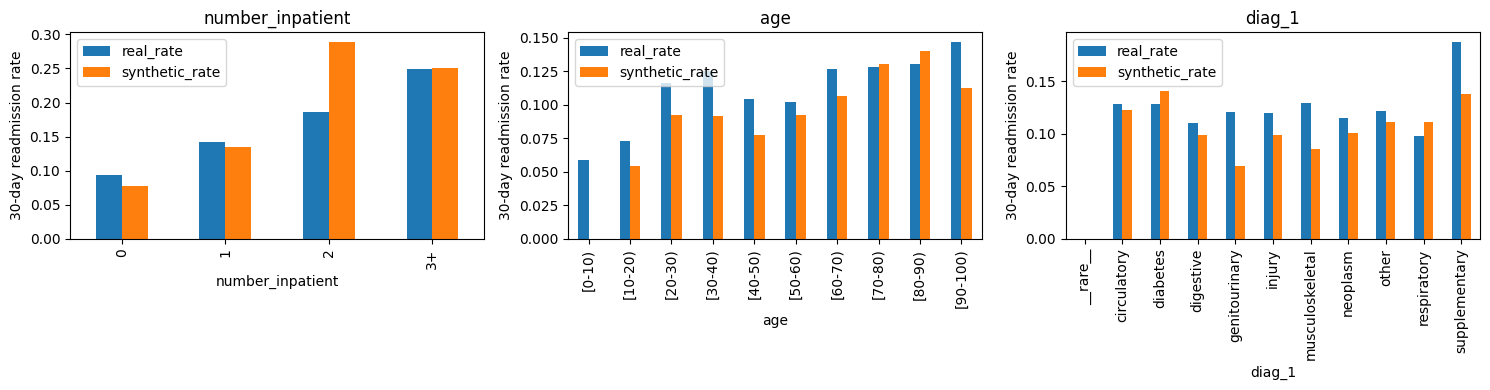

,duplicate_full_rows,exact_seed_match_rate,medication_inconsistency_rate,excluded_discharge_rate
synthetic,0,0.0,0.0,0.0


In [24]:
reports_dir = ARTIFACT_DIR / "reports"
reports_dir.mkdir(exist_ok=True)

def group_readmission_table(frame, column):
    data = frame.copy()
    if column == "number_inpatient":
        data[column] = pd.cut(data[column], [-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"]).astype(str)
    return data.groupby(column, observed=True)["target"].agg(rate="mean", n="size")

def audit_records(frame):
    active = frame[MEDICATIONS].isin(["Steady", "Up", "Down"]).any(axis=1)
    changed = frame[MEDICATIONS].isin(["Up", "Down"]).any(axis=1)
    medication_error = frame.diabetesMed.ne(np.where(active, "Yes", "No")) | frame.change.ne(np.where(changed, "Ch", "No"))
    return dict(duplicate_full_rows=int(payload_hashes(frame).duplicated().sum()),
                exact_seed_match_rate=float(payload_hashes(frame).isin(set(payload_hashes(real_seed))).mean()),
                medication_inconsistency_rate=float(medication_error.mean()),
                excluded_discharge_rate=float(frame.discharge_disposition_id.isin(excluded_dispositions).mean()))

marginal_rows = []
for col in ["gender", "age", "race", "insulin", "A1Cresult", "target"]:
    real_distribution = real_validation[col].value_counts(normalize=True)
    synthetic_distribution = synthetic[col].value_counts(normalize=True)
    comparison = pd.concat([real_distribution.rename("real_validation"),
                            synthetic_distribution.rename("synthetic")], axis=1).fillna(0)
    comparison["absolute_gap"] = (comparison.real_validation - comparison.synthetic).abs()
    comparison.to_csv(reports_dir / f"distribution_{col}.csv")
    marginal_rows.append(dict(feature=col, total_variation=float(0.5 * comparison.absolute_gap.sum()),
                              largest_category_gap=float(comparison.absolute_gap.max())))
marginals = pd.DataFrame(marginal_rows)
marginals.to_csv(reports_dir / "marginal_distances.csv", index=False)
display(marginals.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["number_inpatient", "age", "diag_1"]):
    relation = group_readmission_table(real_validation, col).add_prefix("real_").join(
        group_readmission_table(synthetic, col).add_prefix("synthetic_"), how="outer")
    relation.to_csv(reports_dir / f"readmission_by_{col}.csv")
    relation[["real_rate", "synthetic_rate"]].plot.bar(ax=ax)
    ax.set(title=col, ylabel="30-day readmission rate")
fig.tight_layout()
fig.savefig(reports_dir / "label_relationships.png", dpi=160)
plt.show()
audit = pd.DataFrame([audit_records(synthetic)], index=["synthetic"])
audit.to_csv(reports_dir / "record_consistency.csv")
display(audit)
assert audit.loc["synthetic", "duplicate_full_rows"] == 0
assert audit.loc["synthetic", "exact_seed_match_rate"] == 0
assert audit.loc["synthetic", "medication_inconsistency_rate"] == 0
assert audit.loc["synthetic", "excluded_discharge_rate"] == 0
if (marginals.largest_category_gap > 0.05).any():
    warnings.warn("At least one reviewed marginal differs by more than five percentage points.")


In [25]:
split_path = ARTIFACT_DIR / "membership_split.csv"
split_manifest_path = ARTIFACT_DIR / "split_manifest.json"
if split_manifest_path.exists():
    split_manifest = read_json(split_manifest_path)
    assert split_manifest["dataset_sha256"] == sha256_file(frozen_path)
    assert split_manifest["split_sha256"] == sha256_file(split_path)
    membership = pd.read_csv(split_path, dtype={"record_id": str})
else:
    train_ids, _ = train_test_split(frozen.record_id, train_size=N_SYNTHETIC // 3,
                                    stratify=frozen.target, random_state=SEED)
    membership = pd.DataFrame({"record_id": frozen.record_id,
                               "member": frozen.record_id.isin(set(train_ids)).astype(int)})
    membership.to_csv(split_path, index=False)
    write_json(split_manifest_path, dict(dataset_sha256=sha256_file(frozen_path),
                                         split_sha256=sha256_file(split_path), seed=SEED))
joined = frozen.merge(membership, on="record_id", validate="one_to_one")
target_train = joined.loc[joined.member == 1].drop(columns="member").reset_index(drop=True)
target_test = joined.loc[joined.member == 0].drop(columns="member").reset_index(drop=True)
assert len(target_train) == 3_000 and len(target_test) == 6_000
assert set(payload_hashes(target_train)).isdisjoint(set(payload_hashes(target_test)))
target_train.to_csv(ARTIFACT_DIR / "target_train_members.csv", index=False)
target_test.to_csv(ARTIFACT_DIR / "target_test_nonmembers.csv", index=False)
display(joined.groupby("member").target.agg(records="size", positive_rate="mean"))


,records,positive_rate
member,,
0,6000,0.112167
1,3000,0.112333


In [26]:
def make_preprocessor():
    return ColumnTransformer([
        ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
                              ("scaler", StandardScaler())]), SCHEMA["numeric"]),
        ("categorical", OneHotEncoder(categories=[SCHEMA["categories"][c] for c in SCHEMA["categorical"]],
                                      handle_unknown="ignore", sparse_output=False, dtype=np.float32),
         SCHEMA["categorical"]),
    ], remainder="drop")

class ReadmissionMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(nn.Linear(input_dim, 128), nn.ReLU(),
                                     nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 2))
    def forward(self, x):
        return self.network(x)

def train_target_classifier(records):
    seed_everything(SEED)
    preprocessor = make_preprocessor()
    X = preprocessor.fit_transform(records[FEATURES]).astype(np.float32)
    y = records.target.to_numpy(np.int64).copy()
    model = ReadmissionMLP(X.shape[1]).to(DEVICE)
    loader = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                        batch_size=TARGET_BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=TARGET_LEARNING_RATE,
                                 weight_decay=TARGET_WEIGHT_DECAY)
    history = []
    for epoch in range(TARGET_EPOCHS):
        model.train(); total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)
            loss.backward(); optimizer.step()
            total += loss.item() * len(yb)
        history.append(dict(epoch=epoch + 1, training_cross_entropy=total / len(y)))
    return model, preprocessor, pd.DataFrame(history)

@torch.no_grad()
def predict_outputs(model, preprocessor, records):
    X = preprocessor.transform(records[FEATURES]).astype(np.float32)
    model.eval(); device = next(model.parameters()).device
    logits = torch.cat([model(torch.from_numpy(X[i:i + 1024]).to(device)).cpu()
                        for i in range(0, len(X), 1024)])
    y = torch.from_numpy(records.target.to_numpy(np.int64).copy())
    return logits.numpy(), torch.softmax(logits, 1)[:, 1].numpy(), F.cross_entropy(logits, y, reduction="none").numpy()

def classification_metrics(y, probability):
    probability = np.asarray(probability); prediction = (probability >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    return dict(accuracy=float(accuracy_score(y, prediction)),
                balanced_accuracy=float(balanced_accuracy_score(y, prediction)),
                precision=float(precision_score(y, prediction, zero_division=0)),
                recall=float(recall_score(y, prediction, zero_division=0)),
                f1=float(f1_score(y, prediction, zero_division=0)),
                average_precision=float(average_precision_score(y, probability)),
                auroc=float(roc_auc_score(y, probability)),
                cross_entropy=float(log_loss(y, np.column_stack([1 - probability, probability]), labels=[0, 1])),
                tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

target_checkpoint = ARTIFACT_DIR / "target_model.pt"
target_preprocessor_path = ARTIFACT_DIR / "target_preprocessor.joblib"
target_bundle_path = ARTIFACT_DIR / "target_bundle.json"
if target_bundle_path.exists():
    bundle = read_json(target_bundle_path)
    assert bundle["dataset_sha256"] == sha256_file(frozen_path)
    preprocessor = joblib.load(target_preprocessor_path)
    checkpoint = torch.load(target_checkpoint, map_location="cpu", weights_only=True)
    target_model = ReadmissionMLP(checkpoint["input_dim"]).to(DEVICE)
    target_model.load_state_dict(checkpoint["state_dict"])
    history = pd.read_csv(ARTIFACT_DIR / "target_training_history.csv")
else:
    target_model, preprocessor, history = train_target_classifier(target_train)
    input_dim = preprocessor.transform(target_train[FEATURES].iloc[:1]).shape[1]
    torch.save(dict(state_dict={k: v.detach().cpu() for k, v in target_model.state_dict().items()},
                    input_dim=input_dim), target_checkpoint)
    joblib.dump(preprocessor, target_preprocessor_path)
    history.to_csv(ARTIFACT_DIR / "target_training_history.csv", index=False)
    bundle = dict(dataset_sha256=sha256_file(frozen_path), split_sha256=sha256_file(split_path),
                  checkpoint_sha256=sha256_file(target_checkpoint),
                  preprocessor_sha256=sha256_file(target_preprocessor_path),
                  training=dict(epochs=50, batch_size=128, learning_rate=1e-3,
                                weight_decay=1e-5, hidden_dims=[128, 64], seed=SEED))
    write_json(target_bundle_path, bundle)

metric_rows = []
for split_name, records in [("train", target_train), ("test", target_test)]:
    logits, probability, losses = predict_outputs(target_model, preprocessor, records)
    metrics = classification_metrics(records.target, probability)
    metrics["cross_entropy"] = float(losses.mean())
    metric_rows.append(dict(model="target_mlp", split=split_name, **metrics))
    pd.DataFrame({"record_id": records.record_id, "target": records.target,
                  "logit_0": logits[:, 0], "logit_1": logits[:, 1],
                  "probability_1": probability, "cross_entropy": losses}).to_csv(
        ARTIFACT_DIR / f"target_predictions_{split_name}.csv", index=False)
performance = pd.DataFrame(metric_rows)
performance.to_csv(ARTIFACT_DIR / "target_model_performance.csv", index=False)
display(performance.round(4))


,model,split,accuracy,balanced_accuracy,precision,recall,f1,average_precision,auroc,cross_entropy,tn,fp,fn,tp
0,target_mlp,train,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0019,2663,0,0,337
1,target_mlp,test,0.8603,0.5832,0.3241,0.2259,0.2662,0.2454,0.7031,0.9636,5010,317,521,152


In [27]:
utility_path = ARTIFACT_DIR / "real_holdout_utility.csv"
if utility_path.exists():
    utility = pd.read_csv(utility_path)
else:
    real_utility_train, _ = train_test_split(
        real_seed, train_size=3_000, stratify=real_seed.target, random_state=SEED)
    utility_rows = []
    for name, records in {"TRTR_real_training": real_utility_train,
                          "TSTR_synthetic_training": target_train}.items():
        estimator = Pipeline([("preprocessing", make_preprocessor()),
                              ("classifier", LogisticRegression(max_iter=2000, random_state=SEED))])
        estimator.fit(records[FEATURES], records.target)
        probability = estimator.predict_proba(real_test[FEATURES])[:, 1]
        utility_rows.append(dict(experiment=name, training_n=len(records), test_n=len(real_test),
                                 training_positive_rate=float(records.target.mean()),
                                 **classification_metrics(real_test.target, probability)))
    utility = pd.DataFrame(utility_rows)
    utility.to_csv(utility_path, index=False)
display(utility.round(4))
tstr_auc = float(utility.loc[utility.experiment == "TSTR_synthetic_training", "auroc"].iloc[0])
if tstr_auc < 0.55:
    warnings.warn("TSTR AUROC is below 0.55. Do not describe this synthetic dataset as high-utility without revising the generator.")

assert "record_id" not in FEATURES and "target" not in FEATURES
assert not {"patient_nbr", "encounter_id", "readmitted"}.intersection(FEATURES)
manifest = dict(task="A only", revision=3, run_id=RUN_ID, generator="class_conditional_tabddpm",
                source="UCI Diabetes 130-US Hospitals (1999-2008)", source_license="CC BY 4.0",
                synthetic_rows=len(frozen), target_members=len(target_train),
                target_nonmembers=len(target_test), dataset_sha256=sha256_file(frozen_path),
                split_sha256=sha256_file(split_path), feature_schema_sha256=sha256_file(schema_path),
                tstr_auroc=tstr_auc, privacy_claim="No formal privacy guarantee",
                completed_utc=datetime.now(timezone.utc).isoformat())
write_json(ARTIFACT_DIR / "task_a_manifest.json", manifest)
print("Task A complete. Artifacts:", ARTIFACT_DIR)


,experiment,training_n,test_n,training_positive_rate,accuracy,balanced_accuracy,precision,recall,f1,average_precision,auroc,cross_entropy,tn,fp,fn,tp
0,TRTR_real_training,3000,10000,0.1123,0.8840,0.5159,0.4314,0.0384,0.0705,0.1956,0.6139,0.3527,8796,58,1102,44
1,TSTR_synthetic_training,3000,10000,0.1123,0.8841,0.5129,0.4235,0.0314,0.0585,0.1715,0.5888,0.3699,8805,49,1110,36


Task A complete. Artifacts: /content/drive/MyDrive/mia_task_a/tabddpm_v1


In [28]:
from scipy.special import logsumexp, ndtr
from sklearn.metrics import roc_curve

TASK_B_DIR = ARTIFACT_DIR / "task_b"
TASK_B_DIR.mkdir(exist_ok=True)
N_SHADOWS = 128
SHADOW_COUNTS = [8, 16, 32, 64, 128]
REGIME_EPOCHS = {"underfit": 1, "normal": 15, "overfit": 50}
MAIN_REGIME = "overfit"

def target_signals(logits, labels):
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    rows = np.arange(len(labels))
    true_logit = logits[rows, labels]
    other = logits.copy(); other[rows, labels] = -np.inf
    log_probs = logits - logsumexp(logits, axis=1, keepdims=True)
    return dict(negative_loss=log_probs[rows, labels], true_class_logit=true_logit,
                lira_statistic=true_logit - logsumexp(other, axis=1),
                probability_1=np.exp(log_probs[:, 1]))

def attack_metrics(member, scores):
    member = np.asarray(member, dtype=np.int64); scores = np.asarray(scores, dtype=np.float64)
    if not np.isfinite(scores).all():
        raise ValueError("Attack scores must be finite.")
    fpr, tpr, thresholds = roc_curve(member, scores)
    balanced = 0.5 * (tpr + 1 - fpr); best = int(np.argmax(balanced))
    result = dict(balanced_accuracy=float(balanced[best]),
                  balanced_accuracy_threshold=float(thresholds[best]),
                  auc=float(roc_auc_score(member, scores)))
    for requested in [0.001, 0.01, 0.05, 0.10]:
        eligible = np.flatnonzero(fpr <= requested + 1e-15)
        result[f"tpr_at_{100 * requested:g}pct_fpr"] = float(tpr[eligible].max()) if len(eligible) else 0.0
    return result, pd.DataFrame({"fpr": fpr, "tpr": tpr, "threshold": thresholds})

def offline_lira_scores(shadow_scores, inclusion, observed, fixed_variance=False):
    shadow_scores = np.asarray(shadow_scores, dtype=np.float64)
    inclusion = np.asarray(inclusion, dtype=bool)
    if shadow_scores.shape != inclusion.shape:
        raise ValueError("Shadow scores and masks must align.")
    out = np.where(~inclusion, shadow_scores, np.nan); counts = (~inclusion).sum(axis=0)
    if np.any(counts < 2):
        raise ValueError("Each record needs at least two OUT observations.")
    mean = np.nanmean(out, axis=0)
    std = (np.full(len(mean), np.nanstd(out - mean[None, :], ddof=1)) if fixed_variance
           else np.nanstd(out, axis=0, ddof=1))
    positive = std[np.isfinite(std) & (std > 0)]
    if not len(positive):
        raise ValueError("OUT distributions have no positive variance.")
    floor = max(1e-6, float(np.median(positive)) * 1e-3)
    std = np.where(np.isfinite(std), np.maximum(std, floor), floor)
    return ndtr((np.asarray(observed) - mean) / std), mean, std, counts

membership_labels = frozen.record_id.map(membership.set_index("record_id").member).to_numpy(dtype=np.int64)
labels_all = frozen.target.to_numpy(dtype=np.int64)
assert membership_labels.sum() == len(target_train)
print("Task B:", N_SHADOWS, "shadows; members/nonmembers:",
      int(membership_labels.sum()), int((membership_labels == 0).sum()))


Task B: 128 shadows; members/nonmembers: 3000 6000


In [29]:
main_logits, _, main_losses = predict_outputs(target_model, preprocessor, frozen)
main_signals = target_signals(main_logits, labels_all)
np.testing.assert_allclose(main_signals["negative_loss"], -main_losses, rtol=1e-5, atol=1e-6)
np.savez_compressed(TASK_B_DIR / "target_main_signals.npz",
                    record_ids=frozen.record_id.to_numpy(dtype=str), membership=membership_labels,
                    labels=labels_all, logits=main_logits.astype(np.float32),
                    negative_loss=main_signals["negative_loss"].astype(np.float32),
                    true_class_logit=main_signals["true_class_logit"].astype(np.float32),
                    lira_statistic=main_signals["lira_statistic"].astype(np.float32))
baseline_rows, baseline_rocs = [], {}
for name, key in [("LOSS", "negative_loss"), ("True-class logit", "true_class_logit")]:
    metrics, curve = attack_metrics(membership_labels, main_signals[key])
    baseline_rows.append({"attack": name, **metrics}); curve["attack"] = name
    baseline_rocs[name] = curve
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results.round(6))

shadow_dir = TASK_B_DIR / "shadow_scores"; shadow_dir.mkdir(exist_ok=True)
inclusion_path = TASK_B_DIR / "shadow_inclusion.npy"
pool_positions = np.flatnonzero(membership_labels == 0)
shadow_train_size = len(pool_positions) // 2
if len(pool_positions) % 2 or N_SHADOWS % 2:
    raise ValueError("Complementary-pair design requires even counts.")
if inclusion_path.exists():
    shadow_inclusion = np.load(inclusion_path)
else:
    rng = np.random.default_rng(SEED + 20_240)
    shadow_inclusion = np.zeros((N_SHADOWS, len(frozen)), dtype=bool)
    for pair in range(N_SHADOWS // 2):
        chosen = rng.choice(len(pool_positions), shadow_train_size, replace=False)
        local = np.zeros(len(pool_positions), dtype=bool); local[chosen] = True
        shadow_inclusion[2 * pair, pool_positions[local]] = True
        shadow_inclusion[2 * pair + 1, pool_positions[~local]] = True
    np.save(inclusion_path, shadow_inclusion)
assert shadow_inclusion.shape == (N_SHADOWS, len(frozen))
assert not shadow_inclusion[:, membership_labels == 1].any()
assert np.all(shadow_inclusion.sum(axis=1) == shadow_train_size)
for count in SHADOW_COUNTS:
    assert np.all(shadow_inclusion[:count, membership_labels == 0].sum(axis=0) == count // 2)
assert len(np.unique(shadow_inclusion, axis=0)) == N_SHADOWS
shadow_manifest_path = TASK_B_DIR / "shadow_manifest.json"
expected_shadow_manifest = dict(dataset_sha256=sha256_file(frozen_path),
                                split_sha256=sha256_file(split_path),
                                inclusion_sha256=sha256_file(inclusion_path),
                                n_shadows=N_SHADOWS, shadow_train_size=shadow_train_size,
                                regime_epochs=REGIME_EPOCHS,
                                score_definition="true-class logit minus logsumexp(other logits)")
if shadow_manifest_path.exists() and read_json(shadow_manifest_path) != expected_shadow_manifest:
    raise ValueError("Saved shadow configuration does not match this run.")
write_json(shadow_manifest_path, expected_shadow_manifest)
print("Inclusion matrix:", shadow_inclusion.shape, "| records per shadow:", shadow_train_size)


,attack,balanced_accuracy,balanced_accuracy_threshold,auc,tpr_at_0.1pct_fpr,tpr_at_1pct_fpr,tpr_at_5pct_fpr,tpr_at_10pct_fpr
0,LOSS,0.616417,-0.018652,0.566531,0.000,0.000000,0.052333,0.103333
1,True-class logit,0.616917,1.731242,0.567087,0.001,0.012667,0.052333,0.103000


Inclusion matrix: (128, 9000) | records per shadow: 3000


In [30]:
regime_names = list(REGIME_EPOCHS)
regime_epoch_array = np.array([REGIME_EPOCHS[name] for name in regime_names], dtype=np.int64)

def train_classifier_checkpoints(records, seed):
    seed_everything(seed)
    fitted = make_preprocessor()
    X = np.array(fitted.fit_transform(records[FEATURES]), dtype=np.float32, order="C", copy=True)
    y = np.array(records.target, dtype=np.int64, copy=True)
    if not np.isfinite(X).all() or set(y) != {0, 1}:
        raise ValueError("Classifier training data are invalid.")
    model = ReadmissionMLP(X.shape[1]).to(DEVICE)
    loader = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                        batch_size=TARGET_BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=TARGET_LEARNING_RATE,
                                 weight_decay=TARGET_WEIGHT_DECAY)
    requested, states, history = set(REGIME_EPOCHS.values()), {}, []
    started = time.perf_counter()
    for epoch in range(1, TARGET_EPOCHS + 1):
        model.train(); total = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(xb), yb)
            loss.backward(); optimizer.step(); total += loss.item() * len(yb)
        history.append(dict(epoch=epoch, training_cross_entropy=total / len(y)))
        if epoch in requested:
            states[epoch] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    return fitted, pd.DataFrame(history), states, time.perf_counter() - started

def valid_shadow_file(path):
    try:
        with np.load(path, allow_pickle=False) as saved:
            return (saved["lira_statistics"].shape == (len(regime_names), len(frozen)) and
                    np.array_equal(saved["epochs"], regime_epoch_array) and
                    np.isfinite(saved["lira_statistics"]).all())
    except Exception:
        return False

shadow_log_rows = []
for shadow_index in range(N_SHADOWS):
    score_path = shadow_dir / f"shadow_{shadow_index:03d}.npz"
    if valid_shadow_file(score_path):
        with np.load(score_path, allow_pickle=False) as saved:
            elapsed = float(saved["training_seconds"])
        shadow_log_rows.append(dict(shadow=shadow_index, status="loaded", training_seconds=elapsed))
        continue
    shadow_records = frozen.loc[shadow_inclusion[shadow_index]].reset_index(drop=True)
    fitted, _, states, elapsed = train_classifier_checkpoints(
        shadow_records, SEED + 10_000 + shadow_index)
    input_dim = fitted.transform(shadow_records[FEATURES].iloc[:1]).shape[1]
    statistics = []
    for epoch in regime_epoch_array:
        model = ReadmissionMLP(input_dim).to(DEVICE)
        model.load_state_dict(states[int(epoch)])
        logits, _, _ = predict_outputs(model, fitted, frozen)
        statistics.append(target_signals(logits, labels_all)["lira_statistic"]); del model
    statistics = np.asarray(statistics, dtype=np.float32)
    temporary = score_path.with_suffix(".tmp")
    with open(temporary, "wb") as stream:
        np.savez_compressed(stream, lira_statistics=statistics, epochs=regime_epoch_array,
                            training_seconds=np.array(elapsed, dtype=np.float64))
    temporary.replace(score_path)
    shadow_log_rows.append(dict(shadow=shadow_index, status="trained", training_seconds=elapsed))
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if (shadow_index + 1) % 16 == 0:
        print(f"Completed {shadow_index + 1}/{N_SHADOWS} shadow models")
shadow_log = pd.DataFrame(shadow_log_rows)
shadow_log.to_csv(TASK_B_DIR / "shadow_training_log.csv", index=False)
shadow_statistics = np.stack([np.load(shadow_dir / f"shadow_{i:03d}.npz", allow_pickle=False)["lira_statistics"]
                              for i in range(N_SHADOWS)])
assert shadow_statistics.shape == (N_SHADOWS, 3, len(frozen))
combined_path = TASK_B_DIR / "shadow_statistics_combined.npz"
with open(combined_path.with_suffix(".tmp"), "wb") as stream:
    np.savez_compressed(stream, lira_statistics=shadow_statistics, inclusion=shadow_inclusion,
                        epochs=regime_epoch_array, regime_names=np.asarray(regime_names),
                        record_ids=frozen.record_id.to_numpy(dtype=str))
combined_path.with_suffix(".tmp").replace(combined_path)
display(shadow_log.groupby("status").agg(models=("shadow", "size"),
                                                total_seconds=("training_seconds", "sum")).round(2))


Completed 16/128 shadow models
Completed 32/128 shadow models
Completed 48/128 shadow models
Completed 64/128 shadow models
Completed 80/128 shadow models
Completed 96/128 shadow models
Completed 112/128 shadow models
Completed 128/128 shadow models


,models,total_seconds
status,,
trained,128,375.91


,attack,balanced_accuracy,balanced_accuracy_threshold,auc,tpr_at_0.1pct_fpr,tpr_at_1pct_fpr,tpr_at_5pct_fpr,tpr_at_10pct_fpr
0,LOSS,0.616417,-0.018652,0.566531,0.000000,0.000000,0.052333,0.103333
1,True-class logit,0.616917,1.731242,0.567087,0.001000,0.012667,0.052333,0.103000
2,Offline LiRA,0.561500,0.526656,0.597558,0.008000,0.042000,0.125000,0.198667
3,Offline LiRA (fixed variance),0.562500,0.730787,0.593223,0.009333,0.031000,0.111667,0.194333


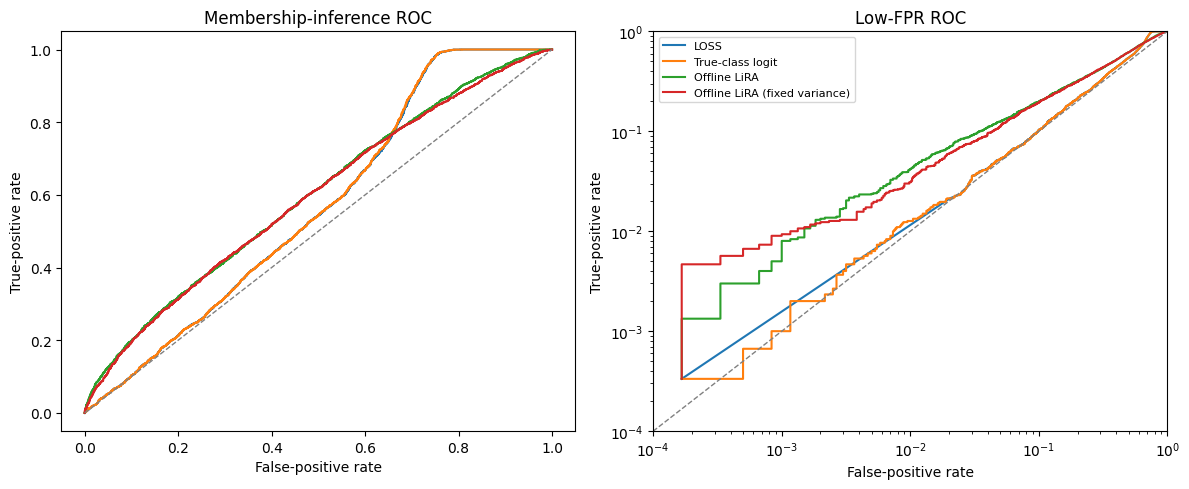

,n_shadows,variance,min_out_observations,balanced_accuracy,balanced_accuracy_threshold,auc,tpr_at_0.1pct_fpr,tpr_at_1pct_fpr,tpr_at_5pct_fpr,tpr_at_10pct_fpr
0,8,per-record variance,4,0.563083,0.327441,0.589025,0.000000,0.005667,0.065667,0.137667
1,8,fixed variance,4,0.563000,0.699797,0.590741,0.005667,0.031333,0.107333,0.175667
2,16,per-record variance,8,0.561750,0.524885,0.593487,0.000333,0.019667,0.097000,0.176000
3,16,fixed variance,8,0.563000,0.562278,0.591141,0.009333,0.032000,0.113333,0.185333
4,32,per-record variance,16,0.562083,0.509908,0.595803,0.007333,0.030333,0.118333,0.196333
5,32,fixed variance,16,0.563083,0.755189,0.592706,0.007333,0.030333,0.111000,0.193667
6,64,per-record variance,32,0.563250,0.520799,0.596016,0.002667,0.036667,0.126000,0.195000
7,64,fixed variance,32,0.563167,0.514665,0.592499,0.007000,0.032333,0.110667,0.194667
8,128,per-record variance,64,0.561500,0.526656,0.597558,0.008000,0.042000,0.125000,0.198667
9,128,fixed variance,64,0.562500,0.730787,0.593223,0.009333,0.031000,0.111667,0.194333


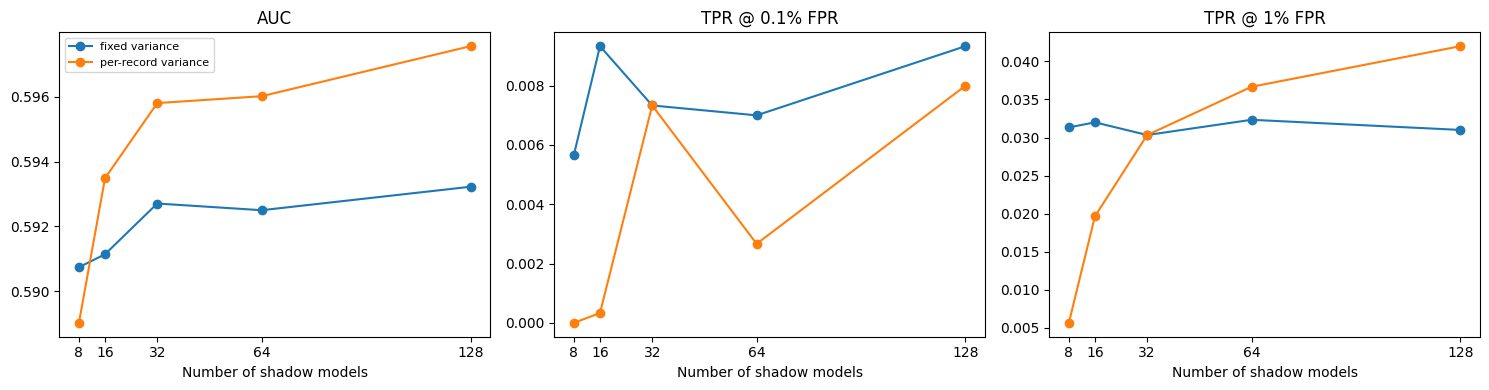

In [31]:
main_index = regime_names.index(MAIN_REGIME)
main_shadow_statistics = shadow_statistics[:, main_index, :]
lira_score, out_mean, out_std, out_counts = offline_lira_scores(
    main_shadow_statistics, shadow_inclusion, main_signals["lira_statistic"])
lira_fixed_score, _, fixed_std, fixed_counts = offline_lira_scores(
    main_shadow_statistics, shadow_inclusion, main_signals["lira_statistic"], fixed_variance=True)
np.testing.assert_array_equal(out_counts, fixed_counts)
np.savez_compressed(TASK_B_DIR / "offline_lira_main.npz",
                    record_ids=frozen.record_id.to_numpy(dtype=str), membership=membership_labels,
                    score=lira_score.astype(np.float32), fixed_variance_score=lira_fixed_score.astype(np.float32),
                    out_mean=out_mean.astype(np.float32), out_std=out_std.astype(np.float32),
                    fixed_std=fixed_std.astype(np.float32), out_counts=out_counts)
attack_rows, roc_frames = list(baseline_rows), list(baseline_rocs.values())
for name, scores in [("Offline LiRA", lira_score), ("Offline LiRA (fixed variance)", lira_fixed_score)]:
    metrics, curve = attack_metrics(membership_labels, scores)
    attack_rows.append({"attack": name, **metrics}); curve["attack"] = name; roc_frames.append(curve)
attack_results = pd.DataFrame(attack_rows); roc_points = pd.concat(roc_frames, ignore_index=True)
attack_results.to_csv(TASK_B_DIR / "attack_results.csv", index=False)
roc_points.to_csv(TASK_B_DIR / "roc_points.csv", index=False)
display(attack_results.round(6))
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, group in roc_points.groupby("attack", sort=False):
    axes[0].plot(group.fpr, group.tpr, label=name)
    axes[1].plot(np.maximum(group.fpr, 1 / (membership_labels == 0).sum()),
                 np.maximum(group.tpr, 1 / (membership_labels == 1).sum()), label=name)
for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    ax.set(xlabel="False-positive rate", ylabel="True-positive rate")
axes[0].set_title("Membership-inference ROC")
axes[1].set(xscale="log", yscale="log", xlim=(1e-4, 1), ylim=(1e-4, 1), title="Low-FPR ROC")
axes[1].legend(fontsize=8); fig.tight_layout()
fig.savefig(TASK_B_DIR / "attack_roc.png", dpi=180); plt.show()

shadow_count_rows = []
for count in SHADOW_COUNTS:
    for variance_name, fixed in [("per-record variance", False), ("fixed variance", True)]:
        scores, _, _, counts = offline_lira_scores(main_shadow_statistics[:count],
            shadow_inclusion[:count], main_signals["lira_statistic"], fixed_variance=fixed)
        metrics, _ = attack_metrics(membership_labels, scores)
        shadow_count_rows.append(dict(n_shadows=count, variance=variance_name,
                                      min_out_observations=int(counts.min()), **metrics))
shadow_count_results = pd.DataFrame(shadow_count_rows)
shadow_count_results.to_csv(TASK_B_DIR / "shadow_count_ablation.csv", index=False)
display(shadow_count_results.round(6))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for variance_name, group in shadow_count_results.groupby("variance"):
    group = group.sort_values("n_shadows")
    axes[0].plot(group.n_shadows, group.auc, marker="o", label=variance_name)
    axes[1].plot(group.n_shadows, group["tpr_at_0.1pct_fpr"], marker="o")
    axes[2].plot(group.n_shadows, group["tpr_at_1pct_fpr"], marker="o")
for ax, title in zip(axes, ["AUC", "TPR @ 0.1% FPR", "TPR @ 1% FPR"]):
    ax.set(xlabel="Number of shadow models", title=title, xticks=SHADOW_COUNTS)
axes[0].legend(fontsize=8); fig.tight_layout()
fig.savefig(TASK_B_DIR / "shadow_count_ablation.png", dpi=180); plt.show()


,regime,epochs,split,accuracy,balanced_accuracy,precision,recall,f1,average_precision,auroc,cross_entropy,tn,fp,fn,tp
0,underfit,1,train,0.887667,0.500000,0.000000,0.000000,0.000000,0.186336,0.643887,0.348881,2663,0,337,0
1,underfit,1,test,0.887833,0.500000,0.000000,0.000000,0.000000,0.196395,0.640465,0.348668,5327,0,673,0
2,normal,15,train,0.922667,0.677817,0.877698,0.362018,0.512605,0.760504,0.948734,0.181711,2646,17,215,122
3,normal,15,test,0.880333,0.536019,0.366864,0.092125,0.147268,0.251466,0.708208,0.376046,5220,107,611,62
4,overfit,50,train,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.001932,2663,0,0,337
5,overfit,50,test,0.860333,0.583173,0.324094,0.225854,0.266200,0.246120,0.703145,0.905642,5010,317,521,152


,regime,epochs,attack,balanced_accuracy,balanced_accuracy_threshold,auc,tpr_at_0.1pct_fpr,tpr_at_1pct_fpr,tpr_at_5pct_fpr,tpr_at_10pct_fpr
0,underfit,1,LOSS,0.502500,-2.704042,0.496927,0.000667,0.007000,0.042000,0.092667
1,underfit,1,True-class logit,0.502667,1.041675,0.495718,0.000667,0.006000,0.048000,0.092667
2,underfit,1,Offline LiRA,0.507333,0.236106,0.498389,0.001667,0.010333,0.046000,0.103333
3,normal,15,LOSS,0.525917,-1.207042,0.527131,0.001333,0.010667,0.055000,0.110000
4,normal,15,True-class logit,0.525667,-0.666314,0.527300,0.001333,0.011000,0.052333,0.109000
5,normal,15,Offline LiRA,0.549917,0.751544,0.565883,0.000667,0.010333,0.064000,0.132333
6,overfit,50,LOSS,0.616417,-0.018652,0.566531,0.000000,0.000000,0.052333,0.103333
7,overfit,50,True-class logit,0.616917,1.731242,0.567087,0.001000,0.012667,0.052333,0.103000
8,overfit,50,Offline LiRA,0.561500,0.526656,0.597558,0.008000,0.042000,0.125000,0.198667


,regime,epochs,accuracy_gap,cross_entropy_gap,auroc_gap
0,underfit,1,-0.000167,-0.000213,0.003422
1,normal,15,0.042333,0.194335,0.240526
2,overfit,50,0.139667,0.903710,0.296855


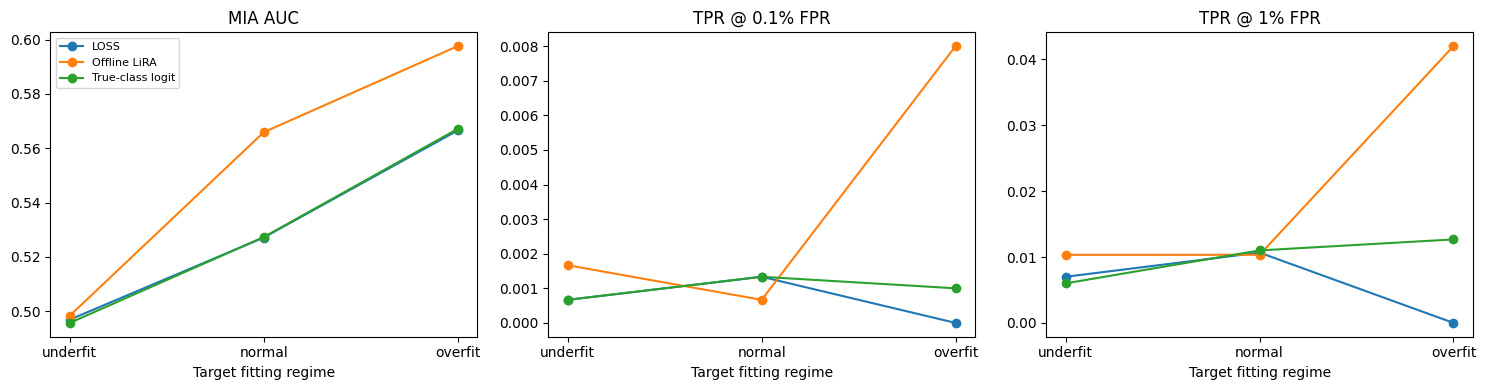

In [32]:
variant_path = TASK_B_DIR / "target_fitting_variants.npz"
variant_history_path = TASK_B_DIR / "target_fitting_history.csv"
if variant_path.exists():
    with np.load(variant_path, allow_pickle=False) as saved:
        target_variant_lira = saved["lira_statistics"]
        target_variant_loss = saved["negative_loss"]
        target_variant_logits = saved["true_class_logit"]
        target_variant_probability = saved["probability_1"]
        if not np.array_equal(saved["epochs"], regime_epoch_array):
            raise ValueError("Saved target fitting epochs do not match.")
    variant_history = pd.read_csv(variant_history_path)
else:
    fitted, variant_history, states, elapsed = train_classifier_checkpoints(target_train, SEED)
    input_dim = fitted.transform(target_train[FEATURES].iloc[:1]).shape[1]
    collected = {key: [] for key in ["lira_statistic", "negative_loss",
                                           "true_class_logit", "probability_1"]}
    for epoch in regime_epoch_array:
        model = ReadmissionMLP(input_dim).to(DEVICE)
        model.load_state_dict(states[int(epoch)])
        logits, _, _ = predict_outputs(model, fitted, frozen)
        signals = target_signals(logits, labels_all)
        for key in collected: collected[key].append(signals[key])
        del model
    target_variant_lira = np.asarray(collected["lira_statistic"], dtype=np.float32)
    target_variant_loss = np.asarray(collected["negative_loss"], dtype=np.float32)
    target_variant_logits = np.asarray(collected["true_class_logit"], dtype=np.float32)
    target_variant_probability = np.asarray(collected["probability_1"], dtype=np.float32)
    np.savez_compressed(variant_path, epochs=regime_epoch_array, lira_statistics=target_variant_lira,
                        negative_loss=target_variant_loss, true_class_logit=target_variant_logits,
                        probability_1=target_variant_probability, training_seconds=np.array(elapsed))
    variant_history.to_csv(variant_history_path, index=False)
fitting_performance_rows, fitting_attack_rows = [], []
for regime_index, regime in enumerate(regime_names):
    probability = target_variant_probability[regime_index]
    for split_name, mask in [("train", membership_labels == 1), ("test", membership_labels == 0)]:
        fitting_performance_rows.append(dict(regime=regime, epochs=REGIME_EPOCHS[regime],
                                             split=split_name,
                                             **classification_metrics(labels_all[mask], probability[mask])))
    matched_lira, _, _, _ = offline_lira_scores(shadow_statistics[:, regime_index, :],
        shadow_inclusion, target_variant_lira[regime_index])
    for attack_name, scores in [("LOSS", target_variant_loss[regime_index]),
                                ("True-class logit", target_variant_logits[regime_index]),
                                ("Offline LiRA", matched_lira)]:
        metrics, _ = attack_metrics(membership_labels, scores)
        fitting_attack_rows.append(dict(regime=regime, epochs=REGIME_EPOCHS[regime],
                                        attack=attack_name, **metrics))
fitting_performance = pd.DataFrame(fitting_performance_rows)
fitting_attacks = pd.DataFrame(fitting_attack_rows)
fitting_performance.to_csv(TASK_B_DIR / "fitting_ablation_classifier.csv", index=False)
fitting_attacks.to_csv(TASK_B_DIR / "fitting_ablation_attacks.csv", index=False)
gap_rows = []
for regime in regime_names:
    rows = fitting_performance[fitting_performance.regime == regime].set_index("split")
    gap_rows.append(dict(regime=regime, epochs=REGIME_EPOCHS[regime],
                         accuracy_gap=rows.loc["train", "accuracy"] - rows.loc["test", "accuracy"],
                         cross_entropy_gap=rows.loc["test", "cross_entropy"] - rows.loc["train", "cross_entropy"],
                         auroc_gap=rows.loc["train", "auroc"] - rows.loc["test", "auroc"]))
fitting_gaps = pd.DataFrame(gap_rows)
fitting_gaps.to_csv(TASK_B_DIR / "fitting_ablation_gaps.csv", index=False)
display(fitting_performance.round(6)); display(fitting_attacks.round(6)); display(fitting_gaps.round(6))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, group in fitting_attacks.groupby("attack"):
    ordered = group.set_index("regime").loc[regime_names]
    axes[0].plot(regime_names, ordered.auc, marker="o", label=name)
    axes[1].plot(regime_names, ordered["tpr_at_0.1pct_fpr"], marker="o")
    axes[2].plot(regime_names, ordered["tpr_at_1pct_fpr"], marker="o")
for ax, title in zip(axes, ["MIA AUC", "TPR @ 0.1% FPR", "TPR @ 1% FPR"]):
    ax.set(xlabel="Target fitting regime", title=title)
axes[0].legend(fontsize=8); fig.tight_layout()
fig.savefig(TASK_B_DIR / "fitting_ablation.png", dpi=180); plt.show()


In [33]:
expected_shadow_files = [shadow_dir / f"shadow_{i:03d}.npz" for i in range(N_SHADOWS)]
assert all(valid_shadow_file(path) for path in expected_shadow_files)
assert set(attack_results.attack) == {"LOSS", "True-class logit", "Offline LiRA",
                                      "Offline LiRA (fixed variance)"}
assert set(shadow_count_results.n_shadows) == set(SHADOW_COUNTS)
assert set(fitting_attacks.regime) == set(regime_names)
assert set(fitting_attacks.attack) == {"LOSS", "True-class logit", "Offline LiRA"}
assert sha256_file(frozen_path) == frozen_manifest["sha256"]
assert sha256_file(split_path) == read_json(split_manifest_path)["split_sha256"]
assert sha256_file(schema_path) == manifest["feature_schema_sha256"]
task_b_manifest = dict(task="B", dataset_sha256=sha256_file(frozen_path),
    split_sha256=sha256_file(split_path), target_checkpoint_sha256=sha256_file(target_checkpoint),
    shadow_inclusion_sha256=sha256_file(inclusion_path),
    combined_shadow_statistics_sha256=sha256_file(combined_path),
    n_shadows=N_SHADOWS, shadow_train_size=shadow_train_size,
    regime_epochs=REGIME_EPOCHS, main_regime=MAIN_REGIME,
    attacks=attack_results.attack.tolist(), required_fpr_levels=[0.001, 0.01, 0.05, 0.10],
    completed_utc=datetime.now(timezone.utc).isoformat())
write_json(TASK_B_DIR / "task_b_manifest.json", task_b_manifest)
print("Task B complete. Main results:", TASK_B_DIR / "attack_results.csv")
print("Shadow-count ablation:", TASK_B_DIR / "shadow_count_ablation.csv")
print("Fitting ablation:", TASK_B_DIR / "fitting_ablation_attacks.csv")


Task B complete. Main results: /content/drive/MyDrive/mia_task_a/tabddpm_v1/task_b/attack_results.csv
Shadow-count ablation: /content/drive/MyDrive/mia_task_a/tabddpm_v1/task_b/shadow_count_ablation.csv
Fitting ablation: /content/drive/MyDrive/mia_task_a/tabddpm_v1/task_b/fitting_ablation_attacks.csv
